In [2]:
!pip install pymysql sqlalchemy pandas

In [3]:
import pandas as pd
from sqlalchemy import create_engine

In [4]:
import pandas as pd

from google.colab import files
uploaded = files.upload()
df = pd.read_csv('datos completos.csv')


print("¡Datos cargados exitosamente desde el CSV!")
print("Total de registros:", len(df))
df.head()

Saving datos completos.csv to datos completos.csv
¡Datos cargados exitosamente desde el CSV!
Total de registros: 19275


,id_tiempo,anio,mes,fecha_completa,id_ruta,municipio_origen_nombre,municipio_destino_nombre,nombre_terminal,clase_vehiculo,total_pasajeros
0,2,2023,1,2023-01-01 00:00:00,3,ARMENIA,MEDELLÍN,T.T. DE ARMENIA,Bus,15
1,2,2023,1,2023-01-01 00:00:00,13,BARRANQUILLA,CARTAGENA DE INDIAS,T.T. DE BARRANQUILLA,Bus,20
2,2,2023,1,2023-01-01 00:00:00,21,ARMENIA,MANIZALES,T.T. DE ARMENIA,Microbús,16
3,2,2023,1,2023-01-01 00:00:00,22,SEVILLA,MANIZALES,T.T. DE ARMENIA,Microbús,5
4,2,2023,1,2023-01-01 00:00:00,27,ARMENIA,POPAYÁN,T.T. DE ARMENIA,Microbús,19


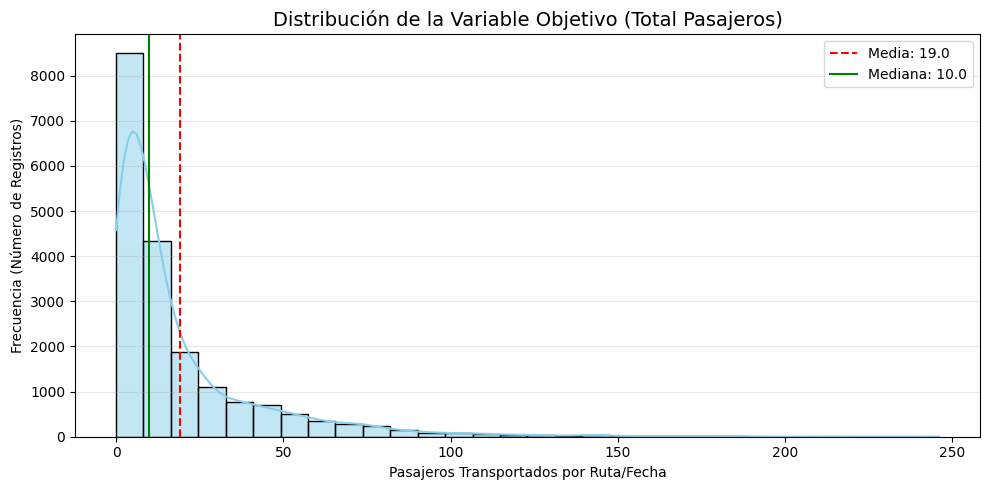

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('datos completos.csv')

plt.figure(figsize=(10, 5))
sns.histplot(df['total_pasajeros'], kde=True, color='skyblue', bins=30)
plt.axvline(df['total_pasajeros'].mean(), color='red', linestyle='--', label=f"Media: {df['total_pasajeros'].mean():.1f}")
plt.axvline(df['total_pasajeros'].median(), color='green', linestyle='-', label=f"Mediana: {df['total_pasajeros'].median():.1f}")

plt.title('Distribución de la Variable Objetivo (Total Pasajeros)', fontsize=14)
plt.xlabel('Pasajeros Transportados por Ruta/Fecha')
plt.ylabel('Frecuencia (Número de Registros)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig('distribucion_variable_objetivo.png', dpi=300)
plt.show()

/tmp/ipykernel_1405/4261281246.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='clase_vehiculo', y='total_pasajeros', data=df, palette='Set2')


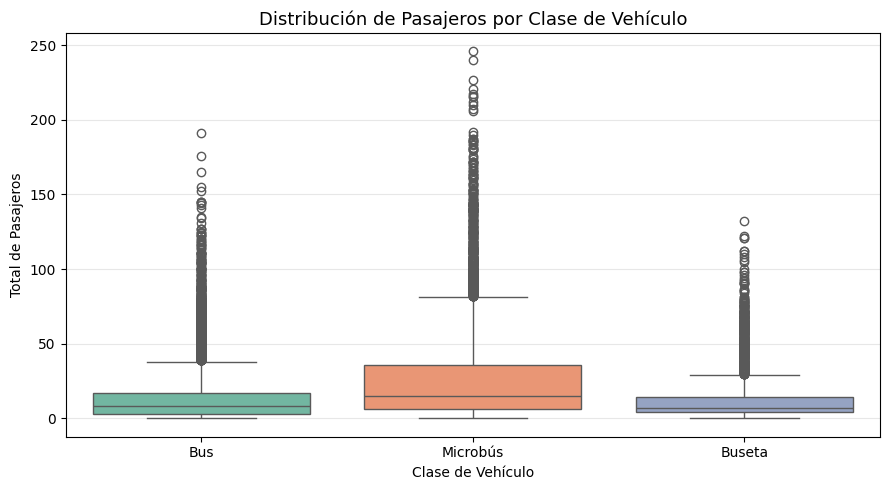

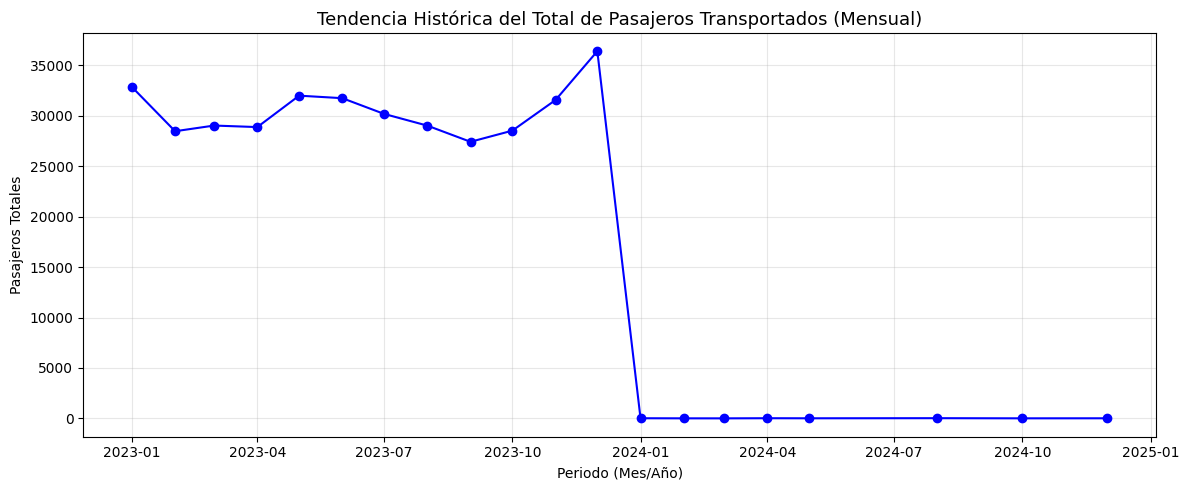

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('datos completos.csv')

plt.figure(figsize=(9, 5))
sns.boxplot(x='clase_vehiculo', y='total_pasajeros', data=df, palette='Set2')
plt.title('Distribución de Pasajeros por Clase de Vehículo', fontsize=13)
plt.xlabel('Clase de Vehículo')
plt.ylabel('Total de Pasajeros')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('eda_por_vehiculo.png', dpi=300)
plt.show()


df['fecha_completa'] = pd.to_datetime(df['fecha_completa'])
tendencia = df.groupby(df['fecha_completa'].dt.to_period('M'))['total_pasajeros'].sum().reset_index()
tendencia['fecha_completa'] = tendencia['fecha_completa'].dt.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(tendencia['fecha_completa'], tendencia['total_pasajeros'], marker='o', color='b', linestyle='-')
plt.title('Tendencia Histórica del Total de Pasajeros Transportados (Mensual)', fontsize=13)
plt.xlabel('Periodo (Mes/Año)')
plt.ylabel('Pasajeros Totales')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('eda_tendencia_temporal.png', dpi=300)
plt.show()

/tmp/ipykernel_1405/2508479960.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='total_pasajeros', y='ruta_nombre', data=top_rutas, palette='Blues_r')


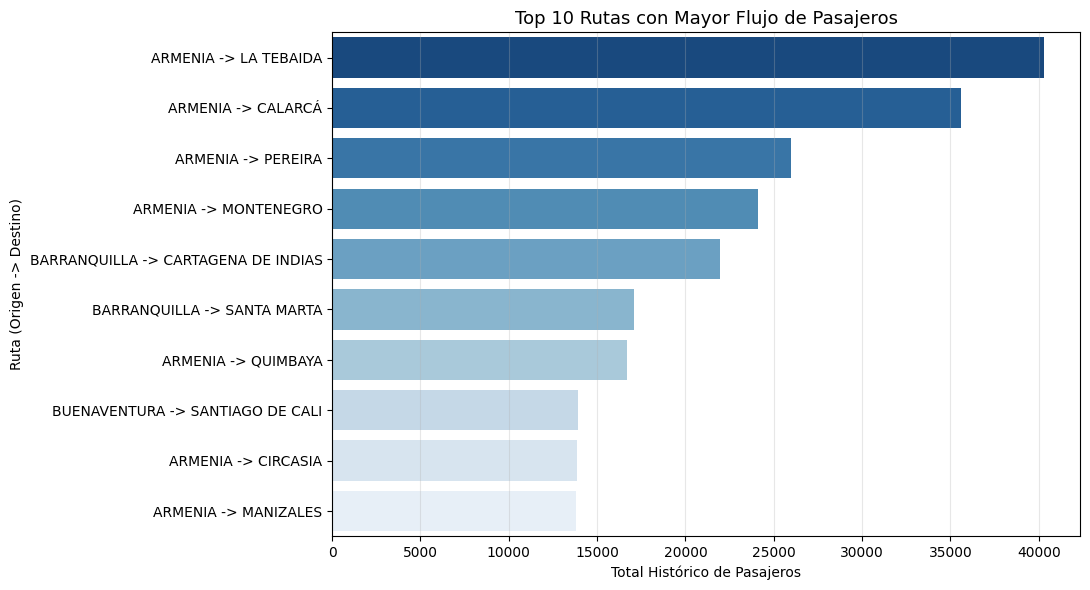

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df['ruta_nombre'] = df['municipio_origen_nombre'] + ' -> ' + df['municipio_destino_nombre']

top_rutas = df.groupby('ruta_nombre')['total_pasajeros'].sum().reset_index()
top_rutas = top_rutas.sort_values(by='total_pasajeros', ascending=False).head(10)

plt.figure(figsize=(11, 6))
sns.barplot(x='total_pasajeros', y='ruta_nombre', data=top_rutas, palette='Blues_r')
plt.title('Top 10 Rutas con Mayor Flujo de Pasajeros', fontsize=13)
plt.xlabel('Total Histórico de Pasajeros')
plt.ylabel('Ruta (Origen -> Destino)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()

plt.savefig('eda_top_rutas.png', dpi=300)
plt.show()

In [8]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Cargar los datos
df = pd.read_csv('datos completos.csv')

# 2. Asegurar el formato de fecha y ordenar cronológicamente
df['fecha_completa'] = pd.to_datetime(df['fecha_completa'])
df = df.sort_values(by=['municipio_origen_nombre', 'municipio_destino_nombre', 'fecha_completa']).reset_index(drop=True)

# 3. Ingeniería de características temporales
df['dia_semana'] = df['fecha_completa'].dt.dayofweek  # 0: Lunes, 6: Domingo
df['es_fin_de_semana'] = df['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

# 4. Creación de Variables Rezagadas (Lags) por ruta
# Esto ayuda al modelo a recordar la demanda de los días anteriores
df['lag_1_dia'] = df.groupby(['municipio_origen_nombre', 'municipio_destino_nombre'])['total_pasajeros'].shift(1)
df['lag_7_dias'] = df.groupby(['municipio_origen_nombre', 'municipio_destino_nombre'])['total_pasajeros'].shift(7)

# Eliminar valores nulos generados por el desfase de los lags iniciales
df = df.dropna().reset_index(drop=True)

# 5. Codificación de variables categóricas (One-Hot Encoding para clase_vehiculo)
df_model = pd.get_dummies(df, columns=['clase_vehiculo', 'nombre_terminal'], drop_first=True)

print("¡Variables y Lags creados con éxito!")
print(f"Dimensiones finales del dataset para el modelo: {df_model.shape}")
df_model.head()

¡Variables y Lags creados con éxito!
Dimensiones finales del dataset para el modelo: (18737, 16)


,id_tiempo,anio,mes,fecha_completa,id_ruta,municipio_origen_nombre,municipio_destino_nombre,total_pasajeros,dia_semana,es_fin_de_semana,lag_1_dia,lag_7_dias,clase_vehiculo_Buseta,clase_vehiculo_Microbús,nombre_terminal_T.T. DE BARRANQUILLA,nombre_terminal_T.T. DE BUENAVENTURA
0,18,2023,1,2023-01-17,9,ARMENIA,"BOGOTÁ, D.C.",29,1,0,34.0,40.0,False,False,False,False
1,23,2023,1,2023-01-22,9,ARMENIA,"BOGOTÁ, D.C.",16,6,1,29.0,39.0,False,False,False,False
2,26,2023,1,2023-01-25,9,ARMENIA,"BOGOTÁ, D.C.",5,2,0,16.0,37.0,False,False,False,False
3,35,2023,2,2023-02-03,9,ARMENIA,"BOGOTÁ, D.C.",13,4,0,5.0,43.0,False,False,False,False
4,41,2023,2,2023-02-09,9,ARMENIA,"BOGOTÁ, D.C.",11,3,0,13.0,42.0,False,False,False,False


In [9]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Preparar las características (X) y la variable objetivo (y)
# Excluimos fecha, textos originales y la variable objetivo
X = df_model.drop(columns=['fecha_completa', 'municipio_origen_nombre', 'municipio_destino_nombre', 'total_pasajeros'], errors='ignore')
y = df_model['total_pasajeros']

# 2. División cronológica o aleatoria (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# 3. Entrenar el modelo de Machine Learning (Random Forest)
modelo = RandomForestRegressor(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

# 4. Realizar predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)

# 5. Calcular métricas de evaluación
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=== RESULTADOS DEL MODELO ===")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

=== RESULTADOS DEL MODELO ===
Error Absoluto Medio (MAE): 9.8722
Raíz del Error Cuadrático Medio (RMSE): 15.5471
Coeficiente de Determinación (R²): -0.3730


In [10]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Preparar las características (X) y la variable objetivo (y)
X = df_model.drop(columns=['fecha_completa', 'municipio_origen_nombre', 'municipio_destino_nombre', 'total_pasajeros'], errors='ignore')
y = df_model['total_pasajeros']

# 2. División cronológica (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# 3. Entrenar el modelo de Regresión Lineal
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

# 4. Realizar predicciones sobre el conjunto de prueba
y_pred_lr = modelo_lr.predict(X_test)

# 5. Calcular métricas de evaluación
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("=== RESULTADOS DE LA REGRESIÓN LINEAL ===")
print(f"Error Absoluto Medio (MAE): {mae_lr:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse_lr:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_lr:.4f}")

=== RESULTADOS DE LA REGRESIÓN LINEAL ===
Error Absoluto Medio (MAE): 10.8189
Raíz del Error Cuadrático Medio (RMSE): 13.3419
Coeficiente de Determinación (R²): -0.0112


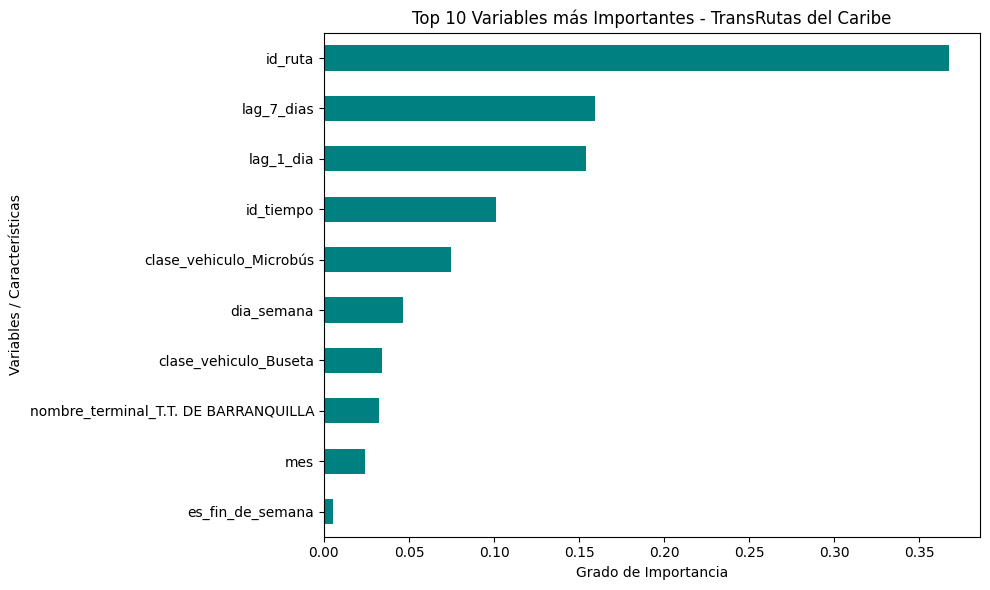

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# Generar gráfico de importancia de variables del Random Forest
importancias = pd.Series(modelo.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 6))
importancias.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Variables más Importantes - TransRutas del Caribe')
plt.xlabel('Grado de Importancia')
plt.ylabel('Variables / Características')
plt.gca().invert_yaxis() # Para que la más importante quede arriba
plt.tight_layout()
plt.show()

In [13]:
# Unir los valores reales con los que predijo el modelo en una sola tablita
df_comparacion_visual = pd.DataFrame({
    'Pasajeros Reales (Lo que pasó)': y_test.values,
    'Pasajeros Predichos (Lo que calculó el modelo)': y_pred.round(0) # .round(0) para ver enteros de pasajeros
})

# Mostrar los primeros 15 ejemplos
print(df_comparacion_visual.head(30))

    Pasajeros Reales (Lo que pasó)  \
0                               27   
1                                9   
2                               14   
3                                9   
4                                6   
5                                1   
6                                4   
7                                6   
8                                6   
9                                5   
10                               7   
11                               0   
12                               7   
13                              10   
14                               7   
15                               2   
16                               6   
17                               7   
18                               9   
19                              19   
20                               5   
21                               1   
22                               5   
23                               9   
24                               9   
25          

In [15]:
# Unir las fechas originales con los valores reales y predichos
df_detalle_predicciones = pd.DataFrame({
    'Fecha': df.loc[X_test.index, 'fecha_completa'].values,
    'Pasajeros Reales': y_test.values,
    'Pasajeros Predichos': y_pred.round(0)
})

# Ver las primeras 10 predicciones con su fecha exacta
print(df_detalle_predicciones.head(50))

        Fecha  Pasajeros Reales  Pasajeros Predichos
0  2023-09-16                27                 11.0
1  2023-09-19                 9                  9.0
2  2023-09-20                14                  8.0
3  2023-09-21                 9                  9.0
4  2023-09-23                 6                 11.0
5  2023-09-25                 1                  8.0
6  2023-09-26                 4                  7.0
7  2023-09-26                 6                  8.0
8  2023-09-27                 6                  7.0
9  2023-09-28                 5                  6.0
10 2023-09-28                 7                  8.0
11 2023-09-29                 0                 10.0
12 2023-09-30                 7                 10.0
13 2023-10-01                10                 10.0
14 2023-10-02                 7                  9.0
15 2023-10-02                 2                  8.0
16 2023-10-04                 6                  8.0
17 2023-10-05                 7               

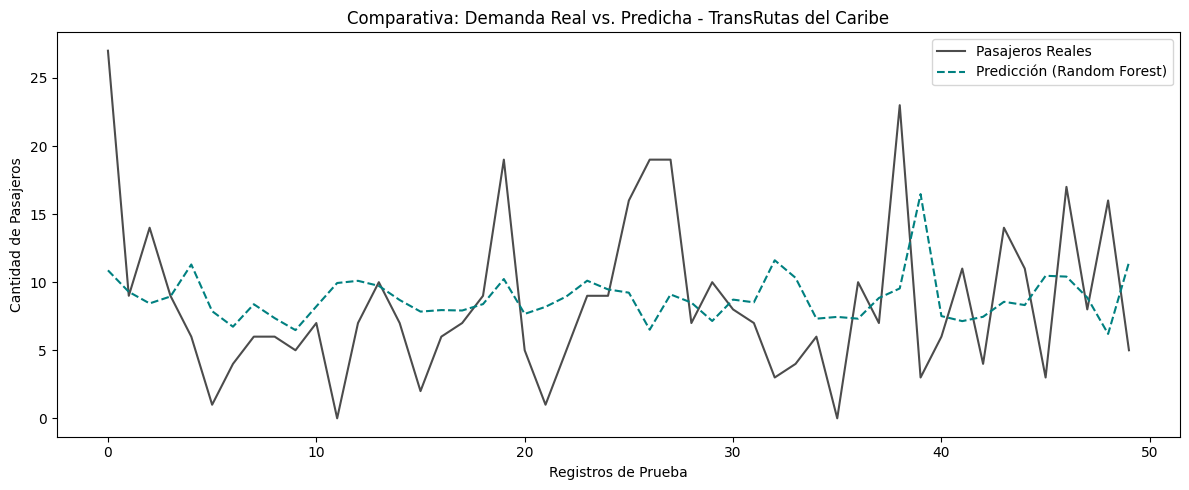

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:50], label='Pasajeros Reales', color='black', alpha=0.7)
plt.plot(y_pred[:50], label='Predicción (Random Forest)', color='teal', linestyle='--')
plt.title('Comparativa: Demanda Real vs. Predicha - TransRutas del Caribe')
plt.xlabel('Registros de Prueba')
plt.ylabel('Cantidad de Pasajeros')
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# Hacer la predicción para TODO el dataset original (todas las filas)
df['pasajeros_predichos'] = modelo.predict(X).round(0)

# Guardar el archivo completo que tendrá exactamente el mismo tamaño de filas que el original
df.to_csv('transrutas_con_todas_las_predicciones.csv', index=False)

# Descargarlo
from google.colab import files
files.download('transrutas_con_todas_las_predicciones.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>